In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as skl

df = pd.read_csv('dataset/ObesityDataSet_raw_and_data_sinthetic.csv')

df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


## Гипотезы
1. Weight будет иметь самую большую ценность.
    2.Случайный лес или градиентный бустинг покажут значительно более высокое качество, чем логистическая регрессия, из-за нелинейных связей между признаками и целевой переменной.
    3. Дерево решений переобучится.
    4. Классы ожирения преставлены неравномерно, поэтому F1 будет ниже accuracy.
    5. Отбор 5 самых ценных признаков не сильно ухудшит качество модели
    6. Люди с начледственным ожирением чаще попадают в классы сверхожирения6 чем люди без него.
    7. Создание нового признака ИМТ сильно повысит точность модели.

In [23]:
class My_Logistic_Regression:
    def __init__(self, learning_rate = 0.01, epochs = 1000):
        self.lr = learning_rate
        self.epochs = epochs
        weights = None
        self.bias = None
    def softmax(self,z):
        exp_z = np.exp(z - np.max(z,axis = 1, keepdims = True))
        return exp_z / np.sum(exp_z, axis = 1,keepdims = True)
    def fit(self, X, Y):
        Y = Y.astype(int)
        n_samples, n_features = X.shape
        n_classes = len(np.unique(Y))
        y_encoded = np.zeros((n_samples, n_classes))
        y_encoded[np.arange(n_samples), Y] = 1
        self.weights = np.zeros((n_features, n_classes))
        self.bias = np.zeros((1, n_classes))

        for i in range(self.epochs):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self.softmax(linear_model)
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y_encoded))
            db = (1 / n_samples) * np.sum(y_predicted - y_encoded, axis=0, keepdims=True)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        y_predicted = self.softmax(linear_model)

        return np.argmax(y_predicted, axis=1)

class CustomDecisionTree:
    def __init__(self, max_depth=5, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.tree = None

    def gini(self, y):
        classes = np.unique(y)
        gini = 1.0
        for cls in classes:
            p = np.sum(y == cls) / len(y)
            gini -= p ** 2
        return gini

    def build_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        if depth >= self.max_depth or len(np.unique(y)) == 1 or n_samples < self.min_samples_split:
            return {'value': np.bincount(y).argmax()} # Лист

        best_gini = float('inf')
        best_feature, best_threshold = None, None

        for feature in range(n_features):
            thresholds = np.unique(X[:, feature])
            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = X[:, feature] > threshold

                if np.sum(left_mask) == 0 or np.sum(right_mask) == 0:
                    continue
                gini_left = self.gini(y[left_mask]) * (np.sum(left_mask) / n_samples)
                gini_right = self.gini(y[right_mask]) * (np.sum(right_mask) / n_samples)
                total_gini = gini_left + gini_right

                if total_gini < best_gini:
                    best_gini = total_gini
                    best_feature = feature
                    best_threshold = threshold

        if best_feature is None:
            return {'value': np.bincount(y).argmax()}
        left_subtree = self.build_tree(X[X[:, best_feature] <= best_threshold], y[X[:, best_feature] <= best_threshold], depth + 1)
        right_subtree = self.build_tree(X[X[:, best_feature] > best_threshold], y[X[:, best_feature] > best_threshold], depth + 1)

        return {'feature': best_feature, 'threshold': best_threshold, 'left': left_subtree, 'right': right_subtree}

    def fit(self, X, y):
        self.tree = self.build_tree(X, y)

    def _predict_single(self, x, tree):
        if 'value' in tree:
            return tree['value']
        if x[tree['feature']] <= tree['threshold']:
            return self._predict_single(x, tree['left'])
        else:
            return self._predict_single(x, tree['right'])

    def predict(self, X):
        return np.array([self._predict_single(x, self.tree) for x in X])
class MyRandomForest:
    def __init__(self, n_estimators = 10, max_depth = 5, max_features = 'sqrt'):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.max_features = max_features
        self.trees = []
    def fit(self, X, Y):
        n_samples, n_features = X.shape

        if self.max_features == 'sqrt':
            n_sub_features = int(np.sqrt(n_features))
        elif isinstance(self.max_features,int):
            n_sub_features = self.max_features
        else:
            n_sub_features = n_features
        for i in range(self.n_estimators):
            indices = np.random.choice(n_samples,n_samples,replace=True)
            x_samples = X[indices]
            y_samples = Y[indices]

            features_indices = np.random.choice(n_features,n_sub_features, replace=True)

            x_samples_sub = x_samples[:, features_indices]
            tree = CustomDecisionTree(max_depth=self.max_depth)
            tree.fit(x_samples_sub,y_samples)

            self.trees.append((tree, features_indices))
    def predict(self, X):
        all_predictions = []

        for tree, feature_indices in self.trees:
            X_sub = X[:, feature_indices]
            all_predictions.append(tree.predict(X_sub))
        all_predictions = np.array(all_predictions)

        final_predictions = []
        for i in range(X.shape[0]):

            patient_votes = all_predictions[:, i]
            winner = np.bincount(patient_votes).argmax()
            final_predictions.append(winner)

        return np.array(final_predictions)

In [24]:
df['BMI'] = df['Weight'] / (df['Height']**2)
X = df.drop(columns=['NObeyesdad'])
Y = df['NObeyesdad'].astype('category').cat.codes
X_encoded = pd.get_dummies(X, drop_first=True)
x_train, x_test, y_train, y_test = skl.model_selection.train_test_split(
    X_encoded.values,
    Y.values,
    test_size = 0.2,
    random_state = 42,
)
scaler = skl.preprocessing.StandardScaler()
X_train_scaled = scaler.fit_transform(x_train)
X_test_scaled = scaler.transform(x_test)

In [25]:
kf = skl.model_selection.KFold(n_splits=5, shuffle=True, random_state=42)

scores_log_reg = []
scores_tree = []
scores_forest = []

for fold, (train_index, test_index) in enumerate(kf.split(X_train_scaled)):
    X_train_fold, X_test_fold = X_train_scaled[train_index], X_train_scaled[test_index]
    y_train_fold, y_test_fold = y_train[train_index], y_train[test_index]

    my_log_reg = My_Logistic_Regression(learning_rate=0.1, epochs=500)
    my_log_reg.fit(X_train_fold, y_train_fold)
    y_predicted_log = my_log_reg.predict(X_test_fold)
    scores_log_reg.append(skl.metrics.accuracy_score(y_test_fold, y_predicted_log))

    my_tree = CustomDecisionTree(max_depth=5)
    my_tree.fit(X_train_fold, y_train_fold)
    y_predicted_tree = my_tree.predict(X_test_fold)
    scores_tree.append(skl.metrics.accuracy_score(y_test_fold, y_predicted_tree))

    my_forest = MyRandomForest(n_estimators=50, max_depth=10, max_features=0.5)
    my_forest.fit(X_train_fold, y_train_fold)
    y_predicted_forest = my_forest.predict(X_test_fold)
    scores_forest.append(skl.metrics.accuracy_score(y_test_fold, y_predicted_forest))
print(f" Accuracy моей логистической регрессии: {np.mean(scores_log_reg):.4f}")
print(f" Accuracy моего дерева решений: {np.mean(scores_tree):.4f}")
print(f"Accuracy моего случайного леса: {np.mean(scores_forest):.4f}")


KeyboardInterrupt: 

In [ ]:
param_log_reg_grid = {
    'C': [0.01, 0.1, 0.5],
    'solver': ['lbfgs', 'saga']
}

grid_search = skl.model_selection.GridSearchCV(
    estimator = skl.linear_model.LogisticRegression(max_iter=1000, random_state=42),
    param_grid = param_log_reg_grid,
    cv = 5,
    scoring = 'accuracy',
    n_jobs = -1, 
    verbose = 0
)
grid_search.fit(X_train_scaled, y_train)

print(f"Лучшие параметры логистической регрессии: {grid_search.best_params_}")
print(f"Лучшая Accuracy логистической регрессии: {grid_search.best_score_:.4f}")

best_log_reg = grid_search.best_estimator_
y_pred_best_log_reg = best_log_reg.predict(X_test_scaled)
print(f"Accuracy лучшей логистической регрессии на тестовой выборке: {skl.metrics.accuracy_score(y_test, y_pred_best_log_reg):.4f}")


param_forest_grid = {
    'n_estimators': [10, 50, 100],
    'max_depth': [5, 10, None]
}

grid_search = skl.model_selection.GridSearchCV(
    estimator = skl.ensemble.RandomForestClassifier(random_state = 42),
    param_grid = param_forest_grid,
    cv = 5,
    scoring = 'accuracy',
    n_jobs = -1
)

grid_search.fit(X_train_scaled, y_train)

print(f"Лучшие параметры случайного леса: {grid_search.best_params_}")
print(f"Лучшая Accuracy случайного леса: {grid_search.best_score_:.4f}")

best_rf = grid_search.best_estimator_
y_pred_best_rf = best_rf.predict(X_test_scaled)
print(f"Accuracy лучшего случайного леса на тестовой выборке: {skl.metrics.accuracy_score(y_test, y_pred_best_rf):.4f}")


Лучшие параметры логистической регрессии: {'C': 0.5, 'solver': 'lbfgs'}
Лучшая Accuracy логистической регрессии: 0.8726
Accuracy лучшей логистической регрессии на тестовой выборке: 0.8723
Лучшие параметры случайного леса: {'max_depth': 10, 'n_estimators': 100}
Лучшая Accuracy случайного леса: 0.9876
Accuracy лучшего случайного леса на тестовой выборке: 0.9882


In [28]:
selector = skl.feature_selection.SelectKBest(score_func=skl.feature_selection.f_classif, k=5)
X_train_kbest = selector.fit_transform(X_train_scaled, y_train)
X_test_kbest = selector.transform(X_test_scaled)

best_rf.fit(X_train_kbest, y_train)
y_pred_kbest = best_rf.predict(X_test_kbest)
acc_kbest = skl.metrics.accuracy_score(y_test, y_pred_kbest)


best_rf.fit(X_train_scaled, y_train)
y_pred_all = best_rf.predict(X_test_scaled)
acc_all = skl.metrics.accuracy_score(y_test, y_pred_all)

print(f'Accuracy со всеми признаками: {acc_all:.4f}')
print(f'Accuracy с 5 лучшими признаками: {acc_all:.4f}')

selected_features = X_encoded.columns[selector.get_support()]
print(f'Оставленные признаки: {list(selected_features)}')


Accuracy со всеми признаками: 0.9882
Accuracy с 5 лучшими признаками: 0.9882
Оставленные признаки: ['Weight', 'BMI', 'Gender_Male', 'family_history_with_overweight_yes', 'CAEC_Sometimes']


In [ ]:
df.info()

df['NObeyesdad'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   str    
 12  FAF                             2111 non-null

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64

<Axes: >

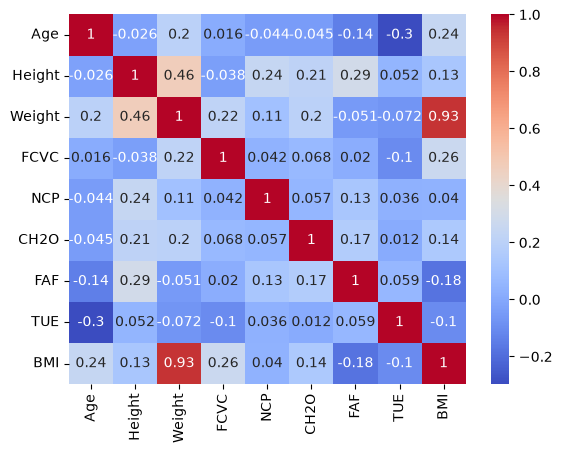

In [ ]:
df.corr(numeric_only=True)
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')

In [ ]:

df.groupby('family_history_with_overweight')['NObeyesdad'].value_counts(normalize=True)*100


Gender  NObeyesdad         
Female  Obesity_Type_III       30.968360
        Insufficient_Weight    16.586769
        Obesity_Type_I         14.956855
        Overweight_Level_I     13.902205
        Normal_Weight          13.518696
        Overweight_Level_II     9.875360
        Obesity_Type_II         0.191755
Male    Obesity_Type_II        27.621723
        Obesity_Type_I         18.258427
        Overweight_Level_II    17.509363
        Normal_Weight          13.670412
        Overweight_Level_I     13.576779
        Insufficient_Weight     9.269663
        Obesity_Type_III        0.093633
Name: proportion, dtype: float64

Выводы по гипотезам:
1. Подтвердилась, Weight и сильно коррелирующий с ним BMI вошли в топ 2 признаков на skl.feature_selection.SelectKBest.
2.Подтвердилась, лес лучше регрессии для многоклассовой классификации.
3. Подтвердилась, дерево переобучилось. Без ограничения max depth модель показывала 100% на train.
4.Подтвердилась, f1 ниже accuracy, следовательно модель чуть хуже справляется с малочисленными классми.
5.Отбор 5 признаков не сильно ухудшил качество.
6. Подтвердилась, доля людей с тяжелой формой ожирения выше у людей с наследственными заболеваниями.
7. Подтвердилось, ожирение диагностируется именно по ИМТ, так что его добавление улучшило качество моделей.